# Detailed Evolution Pipeline

This notebook explains and demonstrates how to run COMPAS and generate derived data products for analysis.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import subprocess
import glob
from pathlib import Path
import sys
import sys; print(sys.executable)
import numpy as np
from src.Simulation.generate_population import GenerateBinaryPopulation
from src.Systems.Populations.BinaryStarPopulation import BinarySystemEvolution
from src.Processing import Processes as Processes
import datetime as dt
import logging
from src.Utils import utils
import astropy.io.fits as fits
import astropy.units as u
import astropy.constants as const
from src.Utils import calculations as calc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
import pandas as pd
print(os.environ.get('COMPAS_ROOT_DIR', 'not set'))

/grad/a.saricaoglu/.conda/envs/compas-env/bin/python
python_version = 3
REPO_ROOT = /data/a.saricaoglu/repo/luxetenebrae/COMPAS
/data/a.saricaoglu/repo/luxetenebrae/COMPAS


### 1. Run COMPAS

In [20]:
mode = 'Detailed_2'
population_generator = GenerateBinaryPopulation(
    mode=mode,
    number_of_systems=5000,                    # or a list: [cfg1, cfg2, ...]
    output_dir=f"/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/{mode}"
)
population_generator.run_COMPAS_simulation()
population_generator.get_info()


[COMPAS] Run 1/5 using config: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_2.yaml
compas_root_dir /data/a.saricaoglu/repo/luxetenebrae/COMPAS
compas_executable_override /data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS
grid_filename None
/data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS --detailed-output  --emit-gravitational-radiation  --population-data-printing  --switch-log  --number-of-systems 1000 --tides-prescription PERFECT --output-path /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_2

COMPAS v03.27.02 (gsl v2.8, boost v1.75.0, HDF5 v1.12.1)
Compact Object Mergers: Population Astrophysics and Statistics
by Team COMPAS (http://compas.science/index.html)
A binary star simulator

Go to https://compas.readthedocs.io/en/latest/index.html for the online documentation
Check https://compas.readthedocs.io/en/latest/pages/whats-new.html to see what's new in the latest release

Start generating binaries at Sun Mar  8 18:08:00 

{'mode': 'Detailed_2',
 'number_of_systems': 5000,
 'repository_root': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae',
 'default_config_file': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_2.yaml',
 'output_directory': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_2'}

In [ ]:
mode = 'Detailed_0'
population_generator = GenerateBinaryPopulation(
    mode=mode,
    number_of_systems=3000,                    # or a list: [cfg1, cfg2, ...]
    output_dir=f"/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/{mode}"
)
population_generator.run_COMPAS_simulation()
population_generator.get_info()

[COMPAS] Run 1/3 using config: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_0.yaml
compas_root_dir /data/a.saricaoglu/repo/luxetenebrae/COMPAS
compas_executable_override /data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS
grid_filename None
/data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS --detailed-output  --emit-gravitational-radiation  --population-data-printing  --switch-log  --number-of-systems 1000 --tides-prescription NONE --output-path /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_0

COMPAS v03.27.02 (gsl v2.8, boost v1.75.0, HDF5 v1.12.1)
Compact Object Mergers: Population Astrophysics and Statistics
by Team COMPAS (http://compas.science/index.html)
A binary star simulator

Go to https://compas.readthedocs.io/en/latest/index.html for the online documentation
Check https://compas.readthedocs.io/en/latest/pages/whats-new.html to see what's new in the latest release

Start generating binaries at Sat Dec 13 15:26:36 202

{'mode': 'Detailed_0',
 'number_of_systems': 3000,
 'repository_root': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae',
 'default_config_file': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_0.yaml',
 'output_directory': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_0'}

In [12]:
mode = 'Detailed_1'
population_generator = GenerateBinaryPopulation(
    mode=mode,
    number_of_systems=3000,                    # or a list: [cfg1, cfg2, ...]
    output_dir=f"/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/{mode}"
)
population_generator.run_COMPAS_simulation()
population_generator.get_info()

[COMPAS] Run 1/3 using config: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_1.yaml
compas_root_dir /data/a.saricaoglu/repo/luxetenebrae/COMPAS
compas_executable_override /data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS
grid_filename None
/data/a.saricaoglu/repo/luxetenebrae/COMPAS/src/bin/COMPAS --detailed-output  --emit-gravitational-radiation  --population-data-printing  --switch-log  --number-of-systems 1000 --tides-prescription KAPIL2025 --output-path /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1

COMPAS v03.27.02 (gsl v2.8, boost v1.75.0, HDF5 v1.12.1)
Compact Object Mergers: Population Astrophysics and Statistics
by Team COMPAS (http://compas.science/index.html)
A binary star simulator

Go to https://compas.readthedocs.io/en/latest/index.html for the online documentation
Check https://compas.readthedocs.io/en/latest/pages/whats-new.html to see what's new in the latest release

Start generating binaries at Sat Dec 13 16:05:1

{'mode': 'Detailed_1',
 'number_of_systems': 3000,
 'repository_root': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae',
 'default_config_file': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/config/configDetailed_1.yaml',
 'output_directory': '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1'}

The config file (`my_compasConfigDefault.yaml`) is used to set the options for COMPAS. You can change the options in the config file to customize the runs. 
In config file, number of systems each run is set to 1000. Therefore, total number of systems generated with this script will be 1000 * number_of_runs.
If you want to change the number of runs, change the number_of_runs variable.
If you want to change the number of systems per run, change the value in the config file  under numericalChoices -> '--number-of-systems'.
Detailed outputs is enabled by default in the config file, so you will get detailed outputs for each run. Change the option from 'True' to 'False' in the config file if you want to disable detailed outputs.
The output directory is set to the current working directory by default. You can change the output directory by setting the environment variable `COMPAS_LOGS_OUTPUT_DIR_PATH` or by changing the value in the config file under stringChoices -> '--output-path'.
Depending on your choices in the config file, you can keep track of important changes or categorise the runs by changing the mode variable below. In this way runs with different configurations can be stored in different directories.
### Before you proceed, run the `Stage_00_run_COMPAS_simulation` as directed above.


## Create a Binary population

In [3]:
mode = 'Detailed_1/'
binary_pop = BinarySystemEvolution(mode=mode)
d, dd = binary_pop.get_data()
binary_pop.get_info()
# 50000 systems took 5m

Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_0.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_1.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_2.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_3.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_4.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_5.h5
Reading file:  /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/runs/Detailed_1/COMPAS_Output/Detailed_Output/BSE_Detailed_Output_6.h5
Reading file:  /data/a.saricaoglu/repo/luxeteneb

{'mode': 'Detailed_1/',
 'name': 'BinarySystemEvolution_Detailed_1/',
 'number_of_systems': 50}

## 2. Purge the simulated systems.
`Stage_01` script loops through the data outputs and check for black holes and MS + BH pairs. If not found, deletes the detailed output file, and records the unique system seed ID into `survivors.txt`. A log file is created in `/logs` directory with the name of the script and the date of the run, consisting of evaluation of all systems and final results fothe population statistic. The function also returns these results for a quick check on this notebook. Note that 'total systems' refers to the number of systems go through the purging pipeline, not all systems generated. (if you are running this script in the same run directory multiple times, it will eliminate and delete systems wihtout BH each time, so total number will be less than number of systems generated in all run sessions.)


In [34]:
proc = Processes.Process(binary_pop)
purge_systems = proc.purge_nonbh_systems(with_logging=True, delete_after_purge=False)
        
print("Purge completed.")
# Print the results
print(purge_systems)

## 3. Extract useful system data from `detailed outputs`

`COMPAS` detailed outouts are written as `BSE_Detailed_Output_j.h5` files in `/luxetenebrae/runs/WD_Enabled_Detailed/COMPAS_Output_i/Detailed_Output`.  For convenience, with `Stage_02DE` script in `/detailed_evolution` we read these files and extract useful data into `.fits` files. These `.fits` outputs are saved in `\files` directory. Similarly to the `Stage_01DE` script, a log file is created in `/logs` directory with the name of the script and the date of the run, consisting of evaluation of all systems and final results fothe population statistic. The function also returns these results for a quick check on this notebook.


In [37]:
proc = Processes.Process(binary_pop)

# Extract system data
results = proc.extract_detailed_system_data('Purged')

print("Data extraction completed.")
# Print the results
print(results)

## 4. Extract useful system data from `general outputs`

Detailed evolution also comes with general `COMPAS_Output_i.h5` in the same directory as the detailed output folder, `/luxetenebrae/runs/WD_Enabled_Detailed/COMPAS_Output_i`. These outputs hold information about certain time stamps of all systems, instead of time evolution of a single system. We can use `Stage_01` and `Stage_02` scripts which are written for the general outputs outide of the detailed_evolution directory to extract data for masks to be used in heatmaps at `Stage_03` for a population statistics analysis. Since we set the mode as `WD_Enabled_Detailed`, the fits files will be saved in the same directory as `Stage_01DE` and `Stage_02DE` scripts, but without a 'DE' (detailed evolution) indicator on the filename.





In [38]:
results = proc.extract_base_system_data()

## 5. Create data masks for the general outputs data

In this step we create data masks to prepare for the next step, which generates heatmap plots.


In [257]:

results = proc.create_base_data_masks()

# Plots


In [4]:
pathToFiles = binary_pop.pathToFiles
print(os.listdir(pathToFiles))
out = [f for f in os.listdir(pathToFiles) if "Purged_processed" in f]
print('Output files found:', out)
detailed_output = []
SP_output = []
MT_output = []
CE_output = []
for f in out:
    print("Reading file: ", pathToFiles + "/" + f)
    data = fits.open(pathToFiles + "/" + f)
    print("Number of tables in the file:", len(data))
    detailed_output.append(data[1])
    SP_output.append(data[2])
    if len(data) > 3:
        MT_output.append(data[3])
    if len(data) > 4:
        CE_output.append(data[4])

['Purged_processed__detailed_outputs_235.fits', 'Purged_processed__detailed_outputs_386.fits', 'Purged_processed__detailed_outputs_20.fits', 'Purged_processed__detailed_outputs_261.fits', 'Purged_processed__detailed_outputs_390.fits', 'Purged_processed__detailed_outputs_27.fits', 'Purged_processed__detailed_outputs_162.fits', 'Purged_processed__detailed_outputs_209.fits', 'Purged_processed__detailed_outputs_347.fits', 'Purged_processed__detailed_outputs_523.fits', 'Purged_processed__detailed_outputs_47.fits', 'Purged_processed__detailed_outputs_264.fits', 'Purged_processed__detailed_outputs_418.fits', 'Purged_processed__detailed_outputs_50.fits', 'Purged_processed__detailed_outputs_166.fits', 'Purged_processed__detailed_outputs_211.fits', 'Purged_processed__detailed_outputs_351.fits', 'Purged_processed__detailed_outputs_508.fits', 'Purged_processed__detailed_outputs_57.fits', 'Purged_processed__detailed_outputs_291.fits', 'Purged_processed__detailed_outputs_429.fits', 'Purged_processed

## Create detailed dictionary

In [5]:
detailed_dict = {}
evolution_status_names = ['Done', 'Error', 'TimesUp','StepsUp','NoTimeStepsRead', 'TimeStepsExhausted', 'TimeStepsNotConsumed', 'SSEerror', 'BinaryError','DCOMergerTime', 'StarsTouching', 'StellarMerger', 'StellarMergerAtBirth', 'DCO', 'WDWD','MasslesRemnant','Unbound','NotStarted','Started']
low_mass_population = []
for Data, Data_SP in zip(detailed_output, SP_output):
    Data = Data.data
    Data_SP = Data_SP.data
    
    # Guard against missing columns
    if 'Seed' not in Data.names:
        print(f"Skipping file: missing 'Seed' column. Available: {Data.names}")
        continue
    mass_1_SP = Data_SP['Mass@ZAMS(1)']
    mass_2_SP = Data_SP['Mass@ZAMS(2)']
    low_mass_mask = (mass_1_SP < 1) | (mass_2_SP < 1)
    low_mass_population.append(np.sum(low_mass_mask))
    seed = Data['Seed'][0]
    # print('seed', seed)
    stellar_type_1 = Data['Stellar_Type_1']
    stellar_type_2 = Data['Stellar_Type_2']
    radius_1 = (Data['Radius(1)']*const.R_sun).to(u.au).value
    radius_2 = (Data['Radius(2)']*const.R_sun).to(u.au).value
    time = Data['Time']
    semimajoraxis = Data['SemiMajorAxis']
    roche_lobe_1 = (Data['RocheLobe(1)']*const.R_sun).to(u.au).value
    roche_lobe_2 = (Data['RocheLobe(2)']*const.R_sun).to(u.au).value
    mass_1 = Data['Mass(1)']
    mass_2 = Data['Mass(2)']
    mass_zams_1 = Data['Mass@ZAMS(1)']
    mass_zams_2 = Data['Mass@ZAMS(2)']
    orbital_period = calc.orbital_period(mass_1, mass_2, semimajoraxis)/u.yr
    mt_history = Data['MT_History']
    evolution_status = Data_SP['Evolution_Status']
    status = evolution_status_names[evolution_status[0]-1]
    eccentricity = Data['Eccentricity']
    periapsiss = calc.periapsis(semimajoraxis, eccentricity)
    merger = Data_SP['Merger']
    merger = [True if m == 1 else False for m in merger]
    statusSP = Data_SP['Evolution_Status'][()]
    mask = np.array([utils.is_ms_bh_pair(st1, st2) for st1, st2 in zip(stellar_type_1, stellar_type_2)])

    time_filtered = time[mask] * 1e6  # Convert Myr to yr
    stype1_filtered = stellar_type_1[mask]
    stype2_filtered = stellar_type_2[mask]
    radius1_filtered = radius_1[mask]
    radius2_filtered = radius_2[mask]
    semimajoraxis_filtered = semimajoraxis[mask]
    eccentricity_filtered = eccentricity[mask]
    mass1_filtered = mass_1[mask]
    mass2_filtered = mass_2[mask]
    orbital_period_filtered = orbital_period[mask]
    bhms_lifetime = time_filtered[-1] - time_filtered[0]
    dt = time_filtered[1:] - time_filtered[:-1]
    if np.any(dt < 0):
        print(f"Skipping seed {seed} with invalid time steps.")
        continue

    detailed_dict[seed] = {
        'time': time_filtered,
        'stellar_type_1': stype1_filtered,
        'stellar_type_2': stype2_filtered,
        'radius_1': radius1_filtered,
        'radius_2': radius2_filtered,
        'semimajoraxis': semimajoraxis_filtered,
        'eccentricity': eccentricity_filtered,
        'orbital_period': orbital_period_filtered,
        'bhms_lifetime': bhms_lifetime,
        'mass_1': mass1_filtered,
        'mass_2': mass2_filtered,
        'status': status,
        'dt': dt
    }


/grad/a.saricaoglu/.conda/envs/compas-env/lib/python3.11/site-packages/astropy/units/quantity.py:648: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


In [29]:
print(mass_1_SP)

[48.08275356]


In [23]:
las = []
for d in detailed_dict.values():
    a = d['semimajoraxis']
    l = d['bhms_lifetime']
    t = d['time']
    las.append(len(a))
    if a[0] < 0:
        # print(d['dt'])
        # print(d['time'])
        # print(d['eccentricity'])
        print(f"Semimajor axis: {a[1]:.3e} AU, BHMS Lifetime: {l:.3e} yr status: {d['status']} component type: {d['stellar_type_2'][0]}")
        print("-" * 40)
    if 1<len(a)< 2:
        stat = d['status']
        comptype =  d['stellar_type_2']
        print(f"Semimajor axis: {a[-1]:.3e} AU, BHMS Lifetime: {l:.3e} yr status: {stat} component type: {comptype}")
        print("-" * 40)
print(f' min semimajor axis length: {min(las)}, max semimajor axis length: {max(las)}, average semimajor axis length: {np.mean(las):.2f}')

Semimajor axis: nan AU, BHMS Lifetime: 1.511e+06 yr status: Unbound component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 5.601e+08 yr status: TimesUp component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 1.788e+07 yr status: Unbound component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 4.724e+07 yr status: TimesUp component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 1.103e+06 yr status: Unbound component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 3.460e+07 yr status: Unbound component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 2.283e+07 yr status: Unbound component type: 1
----------------------------------------
Semimajor axis: nan AU, BHMS Lifetime: 6.584e+06 yr status: Unbound component type: 1
-------------------------

In [22]:
lene = [len(d['eccentricity']) for d in detailed_dict.values()]
print(f'Minimum number of time steps: {min(lene)}, Maximum number of time steps: {max(lene)}, Average number of time steps: {np.mean(lene):.2f}')
print(len([l for l in lene if l > 100]))

Minimum number of time steps: 1, Maximum number of time steps: 99818, Average number of time steps: 3692.19
5651


In [7]:
eu = 0
su = 0
eusu=0
euf = 0
tu = 0
mer = 0
eutu = 0
eumer = 0
lene = [len(d['eccentricity']) for d in detailed_dict.values()]
for d in detailed_dict.values():
    e = d['eccentricity'][0]
    ef = d['eccentricity'][-1]
    time = d['time']
    a = d['semimajoraxis'][0]
    if e > 1:
        print(d['eccentricity'][:10])
        print(f'Eccentricity at bhms start {e} semimajor axis: {a} status in sp {d["status"]} bhms lifetime {d["bhms_lifetime"]} len time {len(time)}')
        eu += 1
        print((d['eccentricity'][1]))
        if d['status'] == 'Unbound':
            eusu += 1
        if d['status'] == 'TimesUp':
            eutu += 1
        if d['status'] == 'StellarMerger':
            eumer += 1
            
    if ef > 1:
        # print(f'Eccentricity at bhms end {ef} status in sp {d["status"]} bhms lifetime {d["bhms_lifetime"]}')
        euf += 1
    if d['status'] == 'Unbound':
        su += 1
    if d['status'] == 'StellarMerger':
        mer += 1
    if d['status'] == 'TimesUp':
        tu += 1
print(f'Number of systems with eccentricity > 1 at BHMS start: {eu}')
print(f'Number of systems with status Unbound: {su}')
print(f'Number of systems with eccentricity > 1 and status Unbound: {eusu}')
print(f'Number of systems with eccentricity > 1 at BHMS end: {euf}')
print(f'Number of systems with status Merger: {mer}')
print(f'Number of systems with status TimesUp: {tu}')
print(f'Number of systems with eccentricity > 1 and status StellarMerger: {eumer}')
print(f'Number of systems with eccentricity > 1 and status TimesUp: {eutu}')

[50.47560065         nan         nan         nan         nan         nan
         nan         nan         nan         nan]
Eccentricity at bhms start 50.47560065223921 semimajor axis: -5.182100046363449 status in sp Unbound bhms lifetime 1510957.1839833688 len time 553
nan
[4.15157608        nan        nan        nan        nan        nan
        nan        nan        nan        nan]
Eccentricity at bhms start 4.151576083923372 semimajor axis: -10.328944321358033 status in sp TimesUp bhms lifetime 560088550.0164073 len time 2298
nan
[16.18643751         nan         nan         nan         nan         nan
         nan         nan         nan         nan]
Eccentricity at bhms start 16.186437510388053 semimajor axis: -4.369093675079934 status in sp Unbound bhms lifetime 17876856.793152183 len time 670
nan
[2.73700943        nan        nan        nan        nan        nan
        nan        nan        nan        nan]
Eccentricity at bhms start 2.737009430585653 semimajor axis: -21.57332732

## Create a dictionary to store the MS-BH system data

In [8]:

ms_bh_dict = {}
c1 = 0
c2 = 0
tskip = 0
for seed, data in detailed_dict.items():
    stype1 = data['stellar_type_1']
    stype2 = data['stellar_type_2']
    e = data['eccentricity'][0]
    a = data['semimajoraxis'][0]
    time = data['time']
    status = data['status']
    if len(time) < 2:
        print(f"Seed {seed} has only {len(time)} time point(s). Skipping.")
        tskip += 1
        continue
    if (a > 0) and (0 <= e < 1):
        bound = True
    else:
        bound = False
    # Find the BH and companion star in the system
    if stype1[0] == 14:
        ms_bh_dict[seed] = {
            'time': data['time'],
            'bh_mass': data['mass_1'],
            'companion_mass': data['mass_2'],
            'bh_radius': data['radius_1'],
            'companion_radius': data['radius_2'],
            'semimajoraxis': data['semimajoraxis'],
            'eccentricity': data['eccentricity'],
            'orbital_period': data['orbital_period'],
            'bhms_lifetime': data['bhms_lifetime'],
            'status': data['status'],
            'bound': bound,
            'dt': data['dt']
        }
        c1 += 1
    elif stype2[0] == 14:
        ms_bh_dict[seed] = {
            'time': data['time'],
            'bh_mass': data['mass_2'],
            'companion_mass': data['mass_1'],
            'bh_radius': data['radius_2'],
            'companion_radius': data['radius_1'],
            'semimajoraxis': data['semimajoraxis'],
            'eccentricity': data['eccentricity'],
            'orbital_period': data['orbital_period'],
            'bhms_lifetime': data['bhms_lifetime'],
            'bound': bound,
            'status': data['status'],
            'dt': data['dt']
        }
        c2 += 1
print(f"Total MS-BH systems found: {len(ms_bh_dict)} (BH as star 1: {c1}, BH as star 2: {c2})")
print(f"Number of systems skipped due to insufficient time points: {tskip}")

Seed 4878 has only 1 time point(s). Skipping.
Seed 8117 has only 1 time point(s). Skipping.
Seed 15890 has only 1 time point(s). Skipping.
Seed 21469 has only 1 time point(s). Skipping.
Total MS-BH systems found: 6209 (BH as star 1: 6208, BH as star 2: 1)
Number of systems skipped due to insufficient time points: 4


In [9]:
# Find the most massive BH and its companion
# Find low mass stars and their companions
max_bh_mass = 0
max_bh_seed = None
low_mass_threshold = 1.0  # M_sun
low_mass_systems = []
for seed, data in ms_bh_dict.items():
    bh_mass = data['bh_mass'][0]
    star_mass = data['companion_mass'][0]
    if star_mass < low_mass_threshold:
        low_mass_systems.append((seed, bh_mass, star_mass, data['status']))
        
    if bh_mass > max_bh_mass:
        max_bh_mass = bh_mass
        max_bh_seed = seed  
    
print(f"Most massive BH seed: {max_bh_seed}, Mass: {max_bh_mass:.2f} M_sun, Companion Mass: {ms_bh_dict[max_bh_seed]['companion_mass'][0]:.2f} M_sun, Status: {ms_bh_dict[max_bh_seed]['status']}")
print(f"Low mass systems: {len(low_mass_systems)}")

Most massive BH seed: 44079, Mass: 16.06 M_sun, Companion Mass: 25.16 M_sun, Status: DCO
Low mass systems: 105


In [43]:
bound_count = sum(1 for b in ms_bh_dict.values() if b['bound'])
unbound_count = len(ms_bh_dict) - bound_count
print(f"Number of bound MS-BH systems: {bound_count}")
print(f"Number of unbound MS-BH systems: {unbound_count}")
for b in ms_bh_dict.values():
    bound = b['bound']
    if bound:
        if np.max(b["eccentricity"]) > 0:
            print(f'max eccentricity: {np.max(b["eccentricity"])}')
    if not bound:
        if np.max(b["eccentricity"]) < 0:
            print(f'max eccentricity: {np.max(b["eccentricity"])}')

Number of bound MS-BH systems: 4953
Number of unbound MS-BH systems: 1256
max eccentricity: 0.455831585939522
max eccentricity: 2.3714374201337736e-16
max eccentricity: 2.2887833992611187e-16
max eccentricity: 0.4663579489200647
max eccentricity: 1.1102230246251565e-16
max eccentricity: 0.5190787371681562
max eccentricity: 0.8716648917291416
max eccentricity: 2.2887848080231445e-16
max eccentricity: 2.482534158953828e-16
max eccentricity: 0.5659346161018377
max eccentricity: 3.3766115072321297e-16
max eccentricity: 3.7238012298709097e-16
max eccentricity: 0.5211233413220745
max eccentricity: 1.1102230246251565e-16
max eccentricity: 2.2247786310271853e-16
max eccentricity: 1.1102230246332591e-16
max eccentricity: 3.1401849173675503e-16
max eccentricity: 1.2412670750411555e-16
max eccentricity: 0.04398260540928758
max eccentricity: 0.49078805154421384
max eccentricity: 5.551115123125783e-17
max eccentricity: 3.140184982536988e-16
max eccentricity: 0.8079299673178107
max eccentricity: 2.2

Bound systems: 4953, Unbound systems: 1256
[np.float64(0.455831585939522), np.float64(2.3714374201337736e-16), np.float64(2.2887833992611187e-16), np.float64(0.4663579489200647), np.float64(1.1102230246251565e-16), np.float64(0.5190787371681562), np.float64(0.8716648917291416), np.float64(2.2887834042111075e-16), np.float64(2.4825341532647385e-16), np.float64(0.5659346161018377), np.float64(3.3766115072321297e-16), np.float64(3.7238012298709097e-16), np.float64(0.5211233413218691), np.float64(1.1102230246251565e-16), np.float64(2.2247786310271853e-16), np.float64(1.1102230246251565e-16), np.float64(3.1401849173675503e-16), np.float64(1.2412670750411555e-16), np.float64(0.04398257713483335), np.float64(0.49078805154421384), np.float64(5.551115123125783e-17), np.float64(3.1401849175052396e-16), np.float64(0.8079299673178107), np.float64(2.2887833992611187e-16), np.float64(3.510833468576758e-16), np.float64(5.551115123125783e-17), np.float64(1.2412670766236366e-16), np.float64(1.241267076

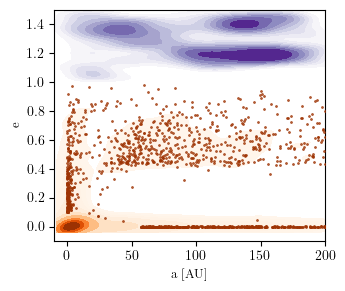

In [ ]:
pathToPlots = '/data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots'
plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.family': 'serif', 'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 12,
                     'legend.fontsize': 9, 'xtick.labelsize': 10, 'ytick.labelsize': 10})
def plot_kde(metrics_x, metrics_y, metric_xname, metric_yname, thresh=0.1, levels=10, bw_adjust=0.6, alpha=[1,1,1], cmaps=None, fig_size=(3.5, 3), fill=[True,True,True], unit_change=(1, 1), reverse_axes=None, scale=('linear', 'linear'), ticks=None, ranges=None,  cut=3.0, save=False, save_as=None):
        
    fig, axs = plt.subplots(1, 1, figsize=fig_size)
    if cmaps is None:
        ccs = ['Purples', 'Oranges', 'Blues', 'Reds']
    else:
        ccs = cmaps
    i=0
    for metric_x, metric_y, cc in zip(metrics_x, metrics_y, ccs):
        def process_metric(m, unit_factor):
            if isinstance(m, (list, tuple)):
                if len(m) > 2:
                    m = m[1:-1]
                if len(m) == 0:
                    return []
                return [float(mm * unit_factor) for mm in m if np.size(mm) > 0]
            elif isinstance(m, np.ndarray) and m.ndim > 0:
                return (m.flatten() * unit_factor).tolist()
            else:
                return [float(m * unit_factor)]
        
        data_x = process_metric(metric_x, unit_change[0])
        data_y = process_metric(metric_y, unit_change[1])
        print(f"Original data points in x: {len(data_x)}")
        print(f"Original data points in y: {len(data_y)}")
        x_array = np.array(data_x)
        y_array = np.array(data_y)

        # Filter invalid
        valid_mask = np.isfinite(x_array) & np.isfinite(y_array)
        x_array = x_array[valid_mask]
        y_array = y_array[valid_mask]
        
        print(f"{len(x_array)} valid points in x")
        print(f"{len(y_array)} valid points in y")
        
        if reverse_axes: 
            # Reverse x-axis if it is plotted on top x axis
            x_array = -x_array if reverse_axes[i][0] else x_array
            y_array = -y_array if reverse_axes[i][1] else y_array
            print(f"  Reversed axes: x reversed={reverse_axes[i][0]}, y reversed={reverse_axes[i][1]}")

        # Check variances, if zero, add a small jitter to avoid KDE failure
        if np.var(x_array) == 0:
            print("  Warning: Zero variance in x data. Adding jitter to avoid KDE failure.")
            x_array += np.random.normal(0,  np.ptp(x_array), size=x_array.shape)
            x_array = np.array(x_array)
        if np.var(y_array) == 0:
            print("  Warning: Zero variance in y data. Adding jitter to avoid KDE failure.")
            y_array = [y + np.random.normal(0,  1e-3) for y in y_array]
            print(f"  Added jitter to y data: new variance = {np.var(y_array):.2e}")
            y_array = np.array(y_array)

        if ranges is not None:
            x_mask = np.ones_like(x_array, dtype=bool)
            y_mask = np.ones_like(y_array, dtype=bool)  
            if ranges[0] is not None:
                x_rng = (ranges[0][0]*unit_change[0], ranges[0][1]*unit_change[0])
                axs.set_xlim(x_rng)
                x_mask = (x_array >= x_rng[0]) & (x_array <= x_rng[1])
            if ranges[1] is not None:
                y_rng = (ranges[1][0]*unit_change[1], ranges[1][1]*unit_change[1])
                axs.set_ylim(y_rng)
                y_mask = (y_array >= y_rng[0]) & (y_array <= y_rng[1])

            x_array = x_array[x_mask & y_mask]
            y_array = y_array[y_mask & x_mask]

        df = pd.DataFrame({metric_xname: x_array, metric_yname: y_array})
        within_percentage = np.sum([x_mask & y_mask]) / len(x_mask) * 100 if ranges is not None and ranges[0] is not None else 100
        # ============ GAUSSIAN KDE ============
        # KDE parameters
        kde_kw = dict(
            fill=fill[i],
            levels=levels,
            thresh=thresh,
            bw_adjust=bw_adjust,
            common_norm=False,
            cut=cut,
            label=None,
            alpha=alpha[i],
        )
        
        sns.kdeplot(x=metric_xname, y=metric_yname, data=df, ax=axs, cmap=cc, **kde_kw)
            
        axs.set_ylabel(f'', fontsize=9)
        axs.set_xlabel(f'', fontsize=9)
        kde = gaussian_kde(np.vstack([x_array, y_array]), bw_method='scott')
        kde.set_bandwidth(kde.factor * kde_kw['bw_adjust'])  # ← Match your bw_adjust=0.7
        density = kde(np.vstack([x_array, y_array]))
        threshold = kde_kw['thresh'] * density.max()
        print(f"  {np.sum(density < threshold)} outliers detected")
        mask_outliers = density < threshold

        print(f"Average x value: {np.mean(x_array):.2f}, Average y value: {np.mean(y_array):.2f}")
        axs.scatter(x_array[mask_outliers], y_array[mask_outliers], color=plt.get_cmap(cc)(0.9), s=2, edgecolor=plt.get_cmap(cc)(0.9), linewidth=0.5, zorder=10, alpha=0.8)
        i += 1
    # ============ FORMATTING ============

    if scale[1] == 'log':
        axs.set_yscale('log')
    if scale[0] == 'log':
        axs.set_xscale('log')

    if ticks:
        axs.set_xticks(ticks[0] if ticks and ticks[0] else None)
        axs.set_yticks(ticks[1] if ticks and ticks[1] else None)

    axs.set_xlabel(f'{metric_xname}')
    axs.set_ylabel(f'{metric_yname}')

    if save:
        if save_as is not None:
            figname = save_as
        else:
            figname = f'compas_{metric_xname}_{metric_yname}_gaussian_kde.png'
        out = os.path.join(pathToPlots, figname)
        fig.savefig(out, dpi=300, bbox_inches='tight')
    
bound_systems = [data for data in ms_bh_dict.values() if data['bound']]
unbound_systems = [data for data in ms_bh_dict.values() if not data['bound']]
print(f"Bound systems: {len(bound_systems)}, Unbound systems: {len(unbound_systems)}")
semimajoraxis_bound = [data['semimajoraxis'][0] for data in bound_systems]
eccentricity_bound = [data['eccentricity'][0] for data in bound_systems]
semimajoraxis_unbound = [data['semimajoraxis'][0] for data in unbound_systems]
eccentricity_unbound = [data['eccentricity'][0] for data in unbound_systems]
print(eccentricity_bound)
print(semimajoraxis_bound)
plot_kde(metrics_x=[semimajoraxis_unbound, semimajoraxis_bound],
         metrics_y=[eccentricity_unbound, eccentricity_bound],
         metric_xname='a [AU]',
         metric_yname='e',
         scale=('linear', 'linear'),
         ranges=[(-10, 200), (-0.1, 1.5)],
         cut=1,
         bw_adjust=0.6,
         reverse_axes=[(True, False), (False, False)],
         thresh=0.1,
         save=False)

In [11]:
def process_timeseries_metric(time_series, metric_series, dt_fixed=100):
    """
    Resample time series to a fixed time step using interpolation.
    
    Parameters:
    -----------
    time_series : list of arrays
        List of time arrays (one per system)
    metric_series : list of arrays
        List of metric arrays (one per system)
    unit_change : list
        [time_unit_factor, metric_unit_factor]
    dt_fixed : float
        Fixed time step for resampling (in years)
    
    Returns:
    --------
    df : dataframe 
    """
    from scipy.interpolate import interp1d
    
    all_times = []
    all_metrics = []
    # dic = {}
    print(len(time_series), len(metric_series))
    for times, metrics in zip(time_series, metric_series):
        if times is None or metrics is None:
            continue
        if len(times) == 0 or len(metrics) == 0:
            continue

        # Flatten arrays and apply unit conversion
        times_flat = np.asarray(times).flatten() 
        metrics_flat = np.asarray(metrics).flatten() 

        if len(times_flat) < 2:  # Need at least 2 points to interpolate
            continue

        # Ensure same length
        min_len = min(len(times_flat), len(metrics_flat))
        if min_len == 0:
            continue

        t_min = times_flat[0]
        t_max = times_flat[-1]
        
        # Generate new time grid
        t_uniform = np.arange(t_min, t_max, dt_fixed)
        if len(t_uniform) < 2:
            # Time series too short for resampling
            all_times.append(times_flat)
            all_metrics.append(metrics_flat)
            continue
        # Interpolate metrics onto uniform grid
        try:
            f_interp = interp1d(times_flat, metrics_flat, 
                            kind='linear',  # or 'cubic' for smoother
                            bounds_error=False, 
                            fill_value='extrapolate')
            
            metric_uniform = f_interp(t_uniform)

            all_times.append(t_uniform)
            all_metrics.append(metric_uniform)     
            # dic[i] = {'time': t_uniform, 'metric': metric_uniform}

        except Exception as e:
            print(f"  Warning: Interpolation failed for system: {e}")
            # Fall back to original data
            all_times.append(times_flat)
            all_metrics.append(metrics_flat)
        
        # df = pd.DataFrame.from_dict(dic)
    return all_times, all_metrics

In [100]:
def multiple_analysis_time_series_2dhistogram_multipanel_stacked(metric_list, time_list,  metric_ylabels, time_ylabel, vmax_percentile=100, metric_percentile=[100, 100, 100], mask_label=None, annotiation_norm=None, ticks=[None, None, None, None], time_unit_change=1, metric_unit_change=[1, 1, 1], metric_masks=None, dt_fixed=1000, survivor_per_at_t=False, analysis_key='All', analysis_zkey='mC', analysis_zlabel=[r'M$_{PBH}$', r'M$_{\odot}$'], scale=['linear', 'linear', 'linear', 'log'], v_key='All', global_ylim=True, normalize=False, metric_ranges=None, time_range=None, v_lim=[None, None], time_bins=1000, metric_bins=1000, use_existing_time_series=True, fig_size=None, save=True, save_as=None):
    """
    Plot 2D histogram of time series metrics in multi-panel layout with stacked subplots.
    Each analysis gets 2 subplots (one per metric) stacked vertically, sharing x-axis (time).
    
    Parameters:
    -----------
    metric_list : list of lists
        List of metric series (e.g., [semimajor_axis_series, eccentricity_series])
    time_list : list
        List containing time series for all systems
    metric_ylabels : list of str
        List of y-axis labels for each metric
    metric_ranges : list of tuples
        [(min1, max1), (min2, max2)] for each metric
    ticks : list of 4 elements
        [time_ticks, metric1_ticks, metric2_ticks, colorbar_ticks]
    scale : list of 4 elements
        [time_scale, metric1_scale, metric2_scale, colorbar_scale]
    """
    nrows = len(metric_list)  # Number of metrics to plot
    ncols = 1
    
    fig, axs = plt.subplots(figsize=fig_size if fig_size is not None else (5, 2*nrows),
                            nrows=nrows, ncols=ncols, sharex=True)
    
    # Make axs iterable even if single subplot
    if nrows == 1:
        axs = [axs]
    
    # Get colormap
    cmap = plt.get_cmap('plasma')
    cmap = cmap.with_extremes(bad=cmap(0))
    
    # Process each metric separately
    all_histograms = [None] * len(metric_list)  # One histogram per metric
    percentage_represented = []
    counts_pre_range = []
    for metric_idx, metric in enumerate(metric_list):
        print(f"\n📊 Processing metric {metric_idx+1}/{len(metric_list)}: {metric_ylabels[metric_idx]}")
        metric_range = metric_ranges[metric_idx] if metric_ranges else None
                    
        # Collect time series data
        all_times = []
        all_metrics = []
                
        time_series = time_list[metric_idx] if time_list and len(time_list) > metric_idx else None
        metric_series = metric
        
        if time_series is None or metric_series is None:
            print(f"  Warning: Skipping metric {metric_idx} - missing data")
            continue
        
        times, metrics = process_timeseries_metric(
            time_series=time_series, 
            metric_series=metric_series,  
            dt_fixed=dt_fixed
        )
        
        if len(times) < 2 or len(metrics) < 2:
            print(f"  Warning: Insufficient data after processing")
            continue
        
        all_times.extend(np.concatenate(times))
        all_metrics.extend(np.concatenate(metrics))
        
        if len(all_times) == 0:
            print(f"  Warning: No data points for metric {metric_idx}")
            continue
        
        # Create histogram
        time_array = np.array(all_times)
        metric_array = np.array(all_metrics)
        
        counts_pre_range.append(len(time_array))

        time_range_used = time_range if time_range else (time_array.min(), time_array.max())
        metric_range_used = metric_range if metric_range else (metric_array.min(), np.percentile(metric_array, metric_percentile[metric_idx]))
        
        bin_width = dt_fixed
        time_bins_array = np.arange(time_range_used[0], time_range_used[1] + bin_width, bin_width)
        
        valid_mask = np.isfinite(time_array) & np.isfinite(metric_array) 
        time_array = time_array[valid_mask]
        metric_array = metric_array[valid_mask]
        
        print(f"  Valid data points: {len(time_array)}")
        
        h, xedges, yedges = np.histogram2d(
            time_array, metric_array,
            bins=[time_bins_array, metric_bins],
            range=[time_range_used, metric_range_used]
        )
        
        xedges = xedges * time_unit_change
        yedges = yedges * metric_unit_change[metric_idx]
        
        all_histograms[metric_idx] = (h, xedges, yedges)
        percentage_rep = len(time_series) / annotiation_norm  * 100
        percentage_represented.append(percentage_rep)
    # Find global vmin/vmax across all metrics
    all_h_values = []
    for hist in all_histograms:
        if hist is not None:
            h, _, _ = hist
            all_h_values.append(h[h > 0])
    
    if len(all_h_values) == 0:
        print("Error: No valid histograms generated")
        return
    
    all_h_flat = np.concatenate(all_h_values)
    vmin = v_lim[0] if v_lim[0] is not None else (all_h_flat.min() if len(all_h_flat) > 0 else 1)
    vmax = v_lim[1] if v_lim[1] is not None else np.percentile(all_h_flat, vmax_percentile)     
    if scale[-1] == 'log':
        from matplotlib.colors import LogNorm
        norm_obj = LogNorm(vmin=vmin, vmax=vmax)
    else:
        from matplotlib.colors import Normalize
        norm_obj = Normalize(vmin=vmin, vmax=vmax)
    
    # Plot all subplots
    first_pcm = None
        
    for metric_idx in range(len(metric_list)):
        row_idx = metric_idx
        ax = axs[row_idx]
        
        hist = all_histograms[metric_idx]
        
        if hist is None:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, 
                ha='center', va='center', fontsize=12)
            continue
        
        h, xedges, yedges = hist
        
        pcm = ax.pcolormesh(
            xedges, yedges, h.T,
            cmap=cmap,
            norm=norm_obj,
            rasterized=True,
            shading='auto'
        )
        
        if first_pcm is None:
            first_pcm = pcm
            
        print(f"Total systems in the histogram for metric {metric_idx}: {h.sum()}")
        if row_idx%2 == 0:
            counts_shown_percentage = h.sum() / counts_pre_range[metric_idx] * 100 if counts_pre_range[metric_idx] > 0 else 0
            mask_str = f'{np.round(counts_shown_percentage, 0):.0f}\% repr.' if mask_label and metric_idx < len(mask_label) else f'{np.round(percentage_rep, 0):.0f}\%'
            ax.text(0.98, 0.95, f'{mask_str}', transform=ax.transAxes, va='top', ha='right', fontsize=9, color='white',
                            bbox=dict(boxstyle='round', facecolor='none', edgecolor='none', alpha=0.0))
            

        # Make x axis thicker on bottom plot
        if row_idx%2 != 0:
            ax.spines['bottom'].set_linewidth(2)
            if annotiation_norm:
                percentage_rep = percentage_represented[metric_idx]
                ax.text(0.98, 0.05, f'{np.round(percentage_rep, 0)}\% {mask_label[metric_idx]}', transform=ax.transAxes, va='bottom', ha='right', fontsize=10, color='white',
                bbox=dict(boxstyle='round', facecolor='none', edgecolor='none', alpha=0))

        # Set y-label
        ax.set_ylabel(metric_ylabels[metric_idx], fontsize=10)
        
        # Set y-scale and ticks for each metric
        metric_scale_idx = metric_idx + 1  # scale[1] for metric1, scale[2] for metric2
        if metric_scale_idx < len(scale) and scale[metric_scale_idx] == 'log':
            ax.set_yscale('log')
        
        tick_idx = metric_idx + 1  # ticks[1] for metric1, ticks[2] for metric2
        if tick_idx < len(ticks) and ticks[tick_idx] is not None:
            ax.set_yticks(ticks[tick_idx])
        
        # Only show x-axis label on bottom subplot
        if row_idx < len(metric_list) - 1:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel(time_ylabel, fontsize=10)
            if ticks[0] is not None:
                ax.set_xticks(ticks[0])
            

    # Add colorbar
    if first_pcm is not None:
        cbar = fig.colorbar(
            first_pcm, 
            ax=axs if isinstance(axs, list) else [axs],
            label='Counts',
            location='top',
            orientation='horizontal',
            pad=0.01,
            cax=fig.add_axes([0.15, 0.98, 0.84, 0.015])
        )
        
        if len(ticks) > 3 and ticks[-1] is not None:
            cbar.set_ticks(ticks[-1])
    
    fig.subplots_adjust(hspace=0.0, wspace=0, left=0.15, right=0.99, top=0.98, bottom=0.05)
    
    if save:
        figname = save_as if save_as else f'multiple_analysis_{"_".join(metric_ylabels)}_2dhistogram_stacked.png'
        out = os.path.join(pathToPlots, figname)
        fig.savefig(out, dpi=300, bbox_inches='tight')
        print(f"\n✓ Figure saved to: {out}")
    else:
        plt.show()
    
    return fig
    


In [13]:
# GEt time series data for semimajor axis and eccentricity
time_series = []
semimajor_axis_series = []
eccentricity_series = []
orbital_period_series = []
for data in ms_bh_dict.values():
    time_series.append(data['time'])
    semimajor_axis_series.append(data['semimajoraxis'])
    eccentricity_series.append(data['eccentricity'])
    orbital_period_series.append(data['orbital_period'])

In [ ]:
dtave = []
time_initial = []
for s in ms_bh_dict.values():
    if s['bound']:
        dtaverage = np.mean(s['dt'])
        dtave.append(dtaverage)
        time_initial.append(s['time'][0])
print(np.mean(dtave))
print(np.min(time_initial)/1e6, np.max(time_initial)/1e6)
print(2e5)

311859.4813512415
3.8742778878699955 766.8923122325418
20000.0


In [14]:
print(np.min(time_series[0]), np.max(time_series[0]))
print(np.min(eccentricity_series[0]), np.max(eccentricity_series[0]))

6143277.6756730545 7015060.418862887
0.028084897602721464 0.455831585939522



📊 Processing metric 1/2: a [AU]
6209 6209
  Valid data points: 15054400

📊 Processing metric 2/2: e
6209 6209
  Valid data points: 15054400
Total systems in the histogram for metric 0: 309228.0
Total systems in the histogram for metric 1: 494086.0

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/bhms_time_series_2dhistogram.png


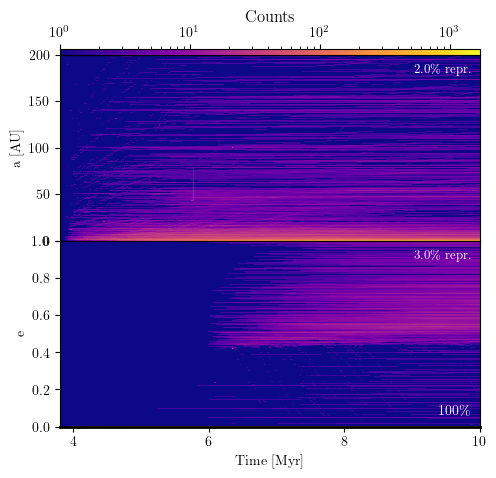

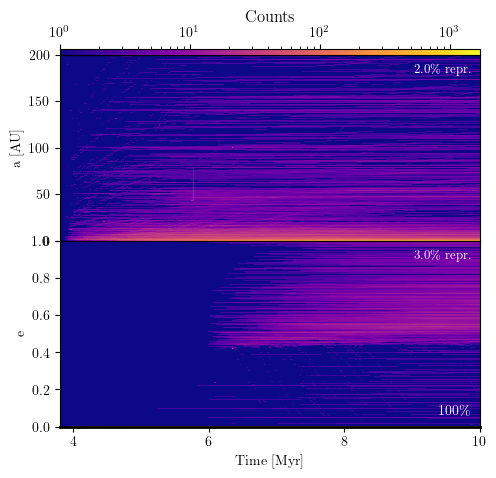

In [ ]:
multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_list=[semimajor_axis_series, eccentricity_series],
    time_list= [time_series, time_series],
    metric_ylabels=[r'a [AU]', r'e'],
    time_ylabel='Time [Myr]',
    metric_bins=200,
    metric_ranges=[(0, 200), (0.0, 1.0)],
    time_range=(3.8e6, 1e7),
    time_unit_change = 1e-6,
    scale=['linear', 'linear', 'linear', 'log'],
    dt_fixed=2e4,
    annotiation_norm=4953,
    ticks=[(4, 6, 8, 10), None, None, None],
    survivor_per_at_t=False,
    save=True,
    save_as='bhms_time_series_2dhistogram.png'
)

In [46]:
print(eccentricity_series[3])

[0. 0. 0. ... 0. 0. 0.]


In [19]:
a_mask = [np.mean(s['semimajoraxis']) < 200 for s in ms_bh_dict.values()]
orbital_period_series_masked_200 = [op.value for op, m in zip(orbital_period_series, a_mask) if  m]
time_series_masked_200 = [t for t, m in zip(time_series, a_mask) if  m]
semimajor_axis_series_masked_200 = [a for a, m in zip(semimajor_axis_series, a_mask) if m]
eccentricity_series_masked_200 = [e for e, m in zip(eccentricity_series, a_mask) if m]
print(len(orbital_period_series_masked_200), len(time_series_masked_200), len(semimajor_axis_series_masked_200))
print(np.sum(a_mask))
print(np.max([np.max(op) for op in orbital_period_series_masked_200]))
print(np.mean([np.mean(op) for op in orbital_period_series_masked_200]))
print(np.mean([np.mean(op) for op in eccentricity_series_masked_200]))

3009 3009 3009
3009
1589760.2607530176
29922.943516489308
0.1246420805974635



📊 Processing metric 1/2: a [AU]
3009 3009
  Valid data points: 5556849

📊 Processing metric 2/2: e
3009 3009
  Valid data points: 5556849
Total systems in the histogram for metric 0: 1308812.0
Total systems in the histogram for metric 1: 1319706.0

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/bhms_time_series_2dhistogram_masked_200.png


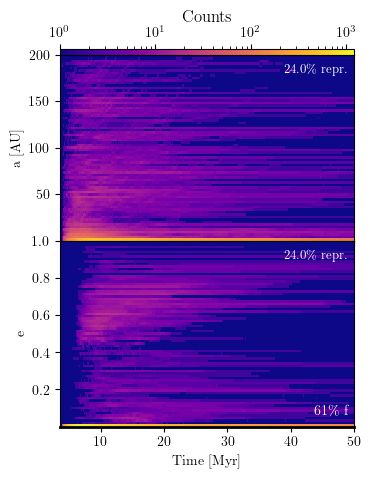

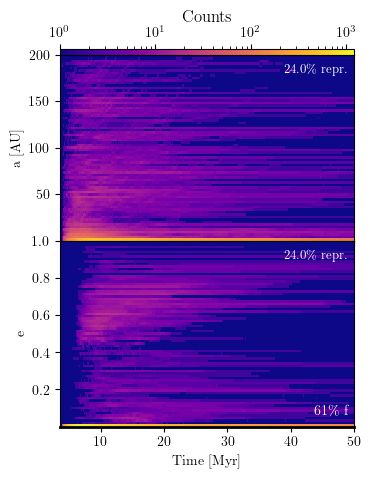

In [44]:
c=5
multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_list=[semimajor_axis_series_masked_200, eccentricity_series_masked_200],
    time_list= [time_series_masked_200, time_series_masked_200],
    metric_ylabels=[r'a [AU]', r'e'],
    time_ylabel='Time [Myr]',
    metric_bins=75,
    metric_ranges=[(0, 200), (0.0, 1.0)],
    ticks=[(2*c, 4*c, 6*c, 8*c, 10*c),(50,100, 150, 200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    time_range=(3.5e6, c*1e7),
    annotiation_norm=4953,
    time_unit_change = 1e-6,
    mask_label=r'of sys. with $a \leq$ 200 AU',
    scale=['linear', 'linear', 'linear', 'log'],
    dt_fixed=2e4,
    survivor_per_at_t=False,
    save=True,
    metric_percentile=[100, 95],
    save_as='bhms_time_series_2dhistogram_masked_200.png',
    fig_size=(3.5, 4)
)


📊 Processing metric 1/2: a [AU]
2094 2094
  Valid data points: 2434664

📊 Processing metric 2/2: e
2094 2094
  Valid data points: 2434664
Total systems in the histogram for metric 0: 870761.0
Total systems in the histogram for metric 1: 878682.0

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/bhms_time_series_2dhistogram_masked_alim50.png


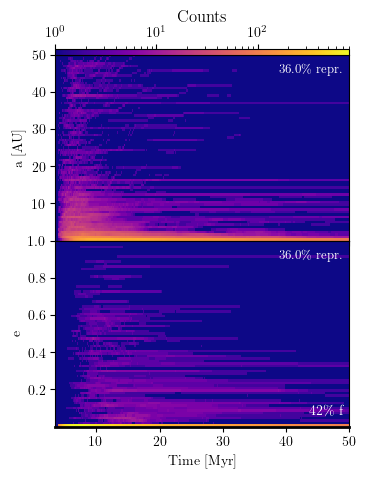

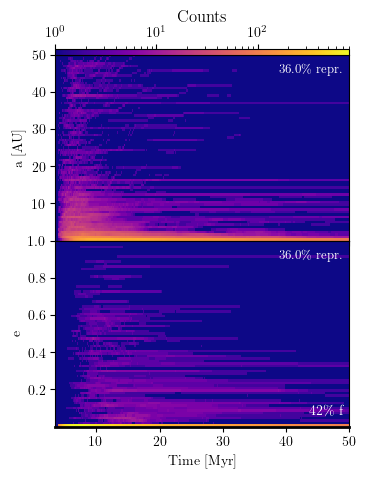

In [45]:
c=5
a_mask = [np.mean(s['semimajoraxis']) < 50 for s in ms_bh_dict.values()]
orbital_period_series_masked_50 = [op.value for op, m in zip(orbital_period_series, a_mask) if  m]
eccentricity_series_masked_50 = [e for e, m in zip(eccentricity_series, a_mask) if  m]
time_series_masked_50 = [t for t, m in zip(time_series, a_mask) if  m]
semimajor_axis_series_masked_50 = [a for a, m in zip(semimajor_axis_series, a_mask) if m]
multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_list=[semimajor_axis_series_masked_50, eccentricity_series_masked_50],
    time_list= [time_series_masked_50, time_series_masked_50],
    metric_ylabels=[r'a [AU]', r'e'],
    time_ylabel='Time [Myr]',
    metric_bins=75,
    metric_ranges=[(0, 50), (0.0, 1.0)],
    ticks=[(2*c, 4*c, 6*c, 8*c, 10*c),(10, 20, 30, 40, 50), (0.2, 0.4, 0.6, 0.8, 1.0)],
    time_range=(3.5e6, c*1e7),
    annotiation_norm=4953,
    time_unit_change = 1e-6,
    mask_label=r'of sys. with $a \leq$ 50 AU',
    scale=['linear', 'linear', 'linear', 'log'],
    dt_fixed=2e4,
    survivor_per_at_t=False,
    metric_percentile=[100, 95],
    save=True,
    save_as='bhms_time_series_2dhistogram_masked_alim50.png',
    fig_size=(3.5, 4)
)


📊 Processing metric 1/4: a [AU]
2094 2094
  Valid data points: 2434664

📊 Processing metric 2/4: e
2094 2094
  Valid data points: 2434664

📊 Processing metric 3/4: a [AU]
3009 3009
  Valid data points: 5556849

📊 Processing metric 4/4: e
3009 3009
  Valid data points: 5556849
Total systems in the histogram for metric 0: 870761.0
Total systems in the histogram for metric 1: 878682.0
Total systems in the histogram for metric 2: 1308812.0
Total systems in the histogram for metric 3: 1319706.0

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/bhms_time_series_2dhistogram_masked_50_200.png


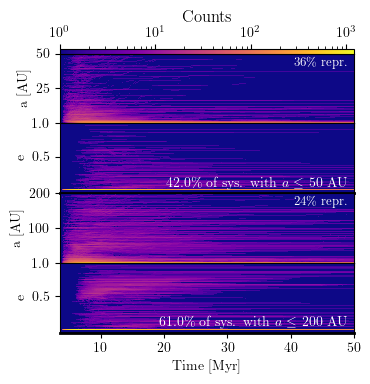

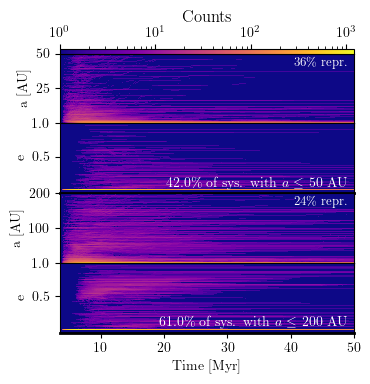

In [101]:
c=5
multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_list=[semimajor_axis_series_masked_50, eccentricity_series_masked_50, semimajor_axis_series_masked_200, eccentricity_series_masked_200],
    time_list= [time_series_masked_50, time_series_masked_50, time_series_masked_200, time_series_masked_200],
    metric_ylabels=[r'a [AU]', r'e', r'a [AU]', r'e'],
    time_ylabel='Time [Myr]',
    metric_bins=75,
    metric_ranges=[(0, 50), (-0.05, 1.0), (0, 200), (-0.05, 1.0)],
    ticks=[(2*c, 4*c, 6*c, 8*c, 10*c), (25, 50), (0.5, 1.0), (100, 200), (0.5, 1.0), None],
    time_range=(3.5e6, c*1e7),
    annotiation_norm=4953,
    time_unit_change = 1e-6,
    metric_unit_change=[1, 1, 1, 1],
    mask_label=[r'of sys. with $a \leq$ 50 AU', r'of sys. with $a \leq$ 50 AU', r'of sys. with $a \leq$ 200 AU', r'of sys. with $a \leq$ 200 AU'],
    scale=['linear', 'linear', 'linear', 'linear', 'linear', 'log'],
    dt_fixed=2e4,
    survivor_per_at_t=False,
    save=True,
    normalize=5e4,
    metric_percentile=[100, 95, 100, 95],
    save_as='bhms_time_series_2dhistogram_masked_50_200.png',
    fig_size=(3.5, 3)
)

In [13]:
c=5
multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_list=[semimajor_axis_series_masked_50, eccentricity_series_masked_50, semimajor_axis_series_masked_200, eccentricity_series_masked_200],
    time_list= [time_series_masked_50, time_series_masked_50, time_series_masked_200, time_series_masked_200],
    metric_ylabels=[r'a [AU]', r'e', r'a [AU]', r'e'],
    time_ylabel='Time [Myr]',
    metric_bins=150,
    metric_ranges=[(0, 50), None, (0, 200), None],
    ticks=[(2*c, 4*c, 6*c, 8*c, 10*c), (5, 20, 35, 50), (-0.2, 0.2), (50, 100, 150, 200), (-0.2, 0.2), None],
    time_range=(3.5e6, c*1e7),
    annotiation_norm=5490,
    time_unit_change = 1e-6,
    metric_unit_change=[1, 1, 1, 1],
    mask_label=[r'of sys. with $a \leq$ 50 AU', r'of sys. with $a \leq$ 50 AU', r'of sys. with $a \leq$ 200 AU', r'of sys. with $a \leq$ 200 AU'],
    scale=['linear', 'linear', 'linear', 'linear', 'linear', 'log'],
    dt_fixed=2e4,
    survivor_per_at_t=False,
    save=True,
    normalize=5e4,
    metric_percentile=[100, 95, 100, 95],
    save_as='bhms_time_series_2dhistogram_masked_50_200_ae.png',
    fig_size=(3.5, 4)
)

NameError: name 'semimajor_axis_series_masked_50' is not defined

Original data points in x: 1254
Original data points in y: 1254
1254 valid points in x
1254 valid points in y
  Reversed axes: x reversed=True, y reversed=False
  50 outliers detected
Average x value: 26.28, Average y value: 4.05
Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False
  34 outliers detected
Average x value: 39.66, Average y value: 8.92


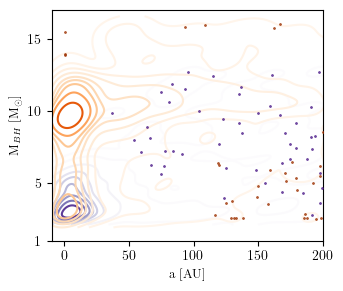

In [35]:
# At the start of the bhms lifetime
mass_bh_bound = [data['bh_mass'][0] for data in ms_bh_dict.values() if data['bound'] == True] 
mass_bh_unbound = [data['bh_mass'][0] for data in ms_bh_dict.values() if data['bound'] == False] 
plot_kde(metrics_x=[semimajoraxis_unbound, semimajoraxis_bound],
         metrics_y=[mass_bh_unbound, mass_bh_bound],
         metric_xname='a [AU]',
         metric_yname=r'M$_{BH}$ [M$_{\odot}$]',
         scale=('linear', 'linear'),
         ranges=[(-10, 200), (1, 17)],
         cut=1,
         bw_adjust=0.7,
         reverse_axes=[(True, False), (False, False)],
         thresh=0.01,
         alpha=[1, 1],
         fill=[False, False],
         ticks=[(0, 50, 100, 150, 200), (1, 5, 10, 15)],
         save=True,
         save_as='bhms_a_vs_mbh_unbound_bound.png',
         fig_size=(3.5, 3))

Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False
  34 outliers detected
Average x value: 39.66, Average y value: 8.92
Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False
  35 outliers detected
Average x value: 39.43, Average y value: 8.92


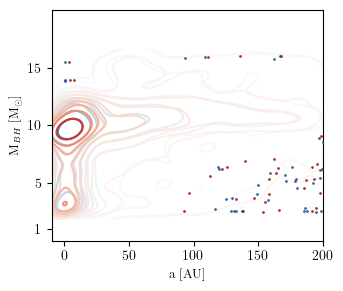

In [39]:
# At the start of the bhms lifetime
mass_bh_bound = [data['bh_mass'][0] for data in ms_bh_dict.values() if data['bound'] == True] 
mass_bh_unbound = [data['bh_mass'][0] for data in ms_bh_dict.values() if data['bound'] == False] 
mass_bh_bound_at_end = [data['bh_mass'][-1] for data in ms_bh_dict.values() if data['bound'] == True] 
semimajoraxis_bound_at_end = [data['semimajoraxis'][-1] for data in ms_bh_dict.values() if data['bound'] == True]
plot_kde(metrics_x=[semimajoraxis_bound, semimajoraxis_bound_at_end],
         metrics_y=[mass_bh_bound, mass_bh_bound_at_end],
         metric_xname='a [AU]',
         metric_yname=r'M$_{BH}$ [M$_{\odot}$]',
         scale=('linear', 'linear'),
         ranges=[(-10, 200), (0, 20)],
         cmaps = ['Blues', 'Reds'],
         cut=1,
         bw_adjust=0.7,
         levels=10,
         reverse_axes=[(False, False), (False, False)],
         thresh=0.01,
         alpha=[1, 0.9],
         fill=[False, False],
         ticks=[(0, 50, 100, 150, 200), (1, 5, 10, 15)],

         save=True,
         save_as='bhms_mass_vs_semimajoraxis_bound_initial_final.png',
         fig_size=(3.5, 3))

Original data points in x: 1254
Original data points in y: 1254
1254 valid points in x
1254 valid points in y
  Reversed axes: x reversed=False, y reversed=False


  0 outliers detected
Average x value: 6.67, Average y value: 5.13
Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False
  0 outliers detected
Average x value: 11.69, Average y value: 8.95


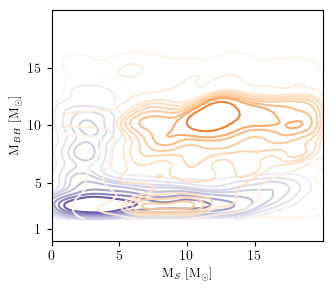

In [38]:
mass_comp_bound = [data['companion_mass'][0] for data in ms_bh_dict.values() if data['bound'] == True]
mass_comp_unbound = [data['companion_mass'][0] for data in ms_bh_dict.values() if data['bound'] == False]
plot_kde(metrics_x=[mass_comp_unbound, mass_comp_bound],
         metrics_y=[mass_bh_unbound, mass_bh_bound],
         metric_xname=r'M$_{S}$ [M$_{\odot}$]',
         metric_yname=r'M$_{BH}$ [M$_{\odot}$]',
         scale=('linear', 'linear'),
         ranges=[(0, 20), (0, 20)],
         cut=1,
         bw_adjust=0.7,
         reverse_axes=[(False, False), (False, False)],
         thresh=0.01,
         alpha=[1, 0.9],
         fill=[False, False],
         ticks=[(0, 5, 10, 15), (1, 5, 10, 15)],
         save_as='bhms_mass_companion_vs_bh_bound_unbound.png',
         save=True,
         fig_size=(3.5, 3))

Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False


  0 outliers detected
Average x value: 11.69, Average y value: 8.95
Original data points in x: 4951
Original data points in y: 4951
4951 valid points in x
4951 valid points in y
  Reversed axes: x reversed=False, y reversed=False
  10 outliers detected
Average x value: 9.41, Average y value: 9.05


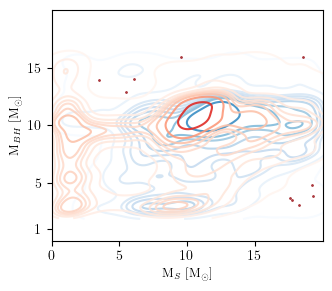

In [40]:
mass_comp_bound_at_end = [data['companion_mass'][-1] for data in ms_bh_dict.values() if data['bound'] == True]
plot_kde(metrics_x=[mass_comp_bound, mass_comp_bound_at_end],
         metrics_y=[mass_bh_bound, mass_bh_bound_at_end],
         metric_xname=r'M$_{S}$ [M$_{\odot}$]',
         metric_yname=r'M$_{BH}$ [M$_{\odot}$]',
         scale=('linear', 'linear'),
         ranges=[(0, 20), (0, 20)],
         cmaps = ['Blues', 'Reds'],
         cut=1,
         bw_adjust=0.7,
         levels=10,
         reverse_axes=[(False, False), (False, False)],
         thresh=0.01,
         alpha=[1, 0.9],
         fill=[False, False],
         ticks=[(0, 5, 10, 15), (1, 5, 10, 15)],
         save=True,
         save_as='bhms_mass_companion_vs_bh_bound_initial_final.png',
         fig_size=(3.5, 3))

In [109]:
from unicodedata import normalize


def voxel_2dhistogram(metric_list, metric_ylabels, voxel_list, voxel_xlabel,metric_ticks=None,voxel_ticks=None, scale=['linear', 'linear', 'log'], metric_ranges=None, voxel_range=None, masks=[None, None], v_lim=[None, None], voxel_bins=20, metric_bins=100, voxel_unit_change= 1, metric_unit_change=[1, 1, 1], normalize=False, annotate_bins=False, annotation_norm=None, fig_size=None, save=True, save_as=None):
    """
    Plot 2D histogram of metrics vs a voxel parameter (single column, multiple rows).
    
    Parameters:
    -----------
    metric_list : list of lists
        List of metric data arrays, one per row (e.g., [mass_data, period_data])
    metric_ylabels : list of str
        Y-axis labels for each metric row
    voxel_data : list
        Voxel parameter data (same for all rows, e.g., semimajor axis bins)
    voxel_xlabel : str
        X-axis label for voxel parameter
    scale : list of 3 str
        [voxel_scale, metric_scale, colorbar_scale] e.g., ['linear', 'linear', 'log']
    metric_ranges : list of tuples
        [(min1, max1), (min2, max2)] for each metric row
    voxel_range : tuple
        (min, max) for voxel parameter
    v_lim : list
        [vmin, vmax] for colorbar
    voxel_bins : int or array
        Number of bins or bin edges for voxel parameter
    metric_bins : int
        Number of bins for metrics
    voxel_unit_change : float
        Factor to multiply voxel data by
    metric_unit_change : list of floats
        Factors to multiply metric data by
    normalize : bool
        Whether to normalize histogram counts
    annotate_bins : bool
        Whether to annotate bins with counts
    """
    nrows = len(metric_list)
    ncols = 1
    
    print(f'Creating {nrows}x{ncols} figure for voxel 2D histograms...')
    fig, axs = plt.subplots(figsize=fig_size if fig_size is not None else (4.5, 3*nrows),
                            nrows=nrows, ncols=ncols, sharex=True)
    
    if nrows == 1:
        axs = [axs]
    
    cmap = plt.get_cmap('plasma')
    cmap = cmap.with_extremes(bad=cmap(0))
    
    histogram_data_all = []
    global_hmin = np.inf
    global_hmax = -np.inf
    
    # Process each metric row
    for row_idx, metric_data in enumerate(metric_list):
        print(f"\n📊 Processing metric {row_idx+1}/{nrows}: {metric_ylabels[row_idx]}")
        voxel_data = voxel_list[row_idx]
        # Apply mask if provided - ADD THIS SECTION
        if masks[row_idx] is not None:
            data_mask = np.asarray(masks[row_idx], dtype=bool)
            if len(data_mask) != len(voxel_data):
                raise ValueError(f"data_mask length ({len(data_mask)}) must match voxel_data length ({len(voxel_data)})")
            
            # Filter voxel data
            voxel_data = [vox for vox, m in zip(voxel_data, data_mask) if m]
            
            # Filter all metrics
            metric_data = [met for met, m in zip(metric_data, data_mask) if m]
            
            print(f"Applied mask: {np.sum(data_mask)}/{len(data_mask)} systems selected")
    
        all_voxel = []
        all_metrics = []
        
        # Pair up voxel and metric data
        for vox, met in zip(voxel_data, metric_data):
            if vox is None or met is None:
                continue
            
            # Handle scalar or array metrics
            if isinstance(met, (list, tuple, np.ndarray)):
                met_averages = np.mean(met) if len(met) > 0 else met
                met_array = np.asarray(met_averages)
                # Repeat voxel value for each metric value
                all_voxel.append(vox * voxel_unit_change)
                all_metrics.append(met_array * metric_unit_change[row_idx])
            else:
                all_voxel.append(vox * voxel_unit_change)
                all_metrics.append(met * metric_unit_change[row_idx])
        
        if len(all_voxel) == 0:
            print(f"  Warning: No data for row {row_idx}")
            histogram_data_all.append(None)
            continue
        
        # Convert to arrays
        voxel_array = np.array(all_voxel)
        metric_array = np.array(all_metrics)
        
        # Filter invalid values
        valid_mask = np.isfinite(voxel_array) & np.isfinite(metric_array)
        voxel_array = voxel_array[valid_mask]
        metric_array = metric_array[valid_mask]
        
        print(f"  Valid data points: {len(voxel_array)}")
        
        if len(voxel_array) == 0:
            histogram_data_all.append(None)
            continue
        
        # Determine ranges
        voxel_range_used = voxel_range if voxel_range else (voxel_array.min(), voxel_array.max())
        if metric_ranges and row_idx < len(metric_ranges):
            metric_range_used = metric_ranges[row_idx]
        else:
            metric_range_used = (metric_array.min(), metric_array.max())
        
        print(f"  Voxel range: {voxel_range_used}, Metric range: {metric_range_used}")
        
        # Create bins
        if scale[0] == 'log':
            voxel_bins_array = np.logspace(
                np.log10(voxel_range_used[0]),
                np.log10(voxel_range_used[1]),
                voxel_bins + 1
            )
        else:
            voxel_bins_array = np.linspace(
                voxel_range_used[0],
                voxel_range_used[1],
                voxel_bins + 1
            )
        
        if scale[1] == 'log':
            metric_bins_array = np.logspace(
                np.log10(metric_range_used[0]),
                np.log10(metric_range_used[1]),
                metric_bins + 1
            )
        else:
            metric_bins_array = np.linspace(
                metric_range_used[0],
                metric_range_used[1],
                metric_bins + 1
            )
        
        # Create histogram
        h, xedges, yedges = np.histogram2d(
            voxel_array, metric_array,
            bins=[voxel_bins_array, metric_bins_array]
        )
        
        counts = h.copy()
        
        if normalize:
            total = np.sum(h)
            if total > 0:
                h = h / normalize
        
        histogram_data_all.append((h, xedges, yedges, counts))
        
        # Track global min/max
        h_nonzero = h[h > 0]
        if len(h_nonzero) > 0:
            global_hmin = min(global_hmin, h_nonzero.min())
            global_hmax = max(global_hmax, h.max())
    
    # Create normalization
    vmin = v_lim[0] if v_lim[0] is not None else (global_hmin if global_hmin != np.inf else 1)
    vmax = v_lim[1] if v_lim[1] is not None else (global_hmax if global_hmax != -np.inf else None)
    
    if scale[2] == 'log':
        from matplotlib.colors import LogNorm
        norm_obj = LogNorm(vmin=vmin, vmax=vmax)
    else:
        from matplotlib.colors import Normalize
        norm_obj = Normalize(vmin=vmin, vmax=vmax)
    
    # Plot
    first_pcm = None
    for row_idx in range(nrows):
        ax = axs[row_idx]
        
        if histogram_data_all[row_idx] is None:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes,
                   ha='center', va='center', fontsize=12)
            continue
        
        h_plot, xedges, yedges, counts = histogram_data_all[row_idx]
        
        # Plot histogram
        pcm = ax.pcolormesh(
            xedges, yedges, h_plot.T,
            cmap=cmap,
            norm=norm_obj,
            rasterized=True,
            shading='auto'
        )
        
        if first_pcm is None:
            first_pcm = pcm
        
        # Annotations
        if annotate_bins:
            x_centers = (xedges[:-1] + xedges[1:]) / 2
            y_centers = (yedges[:-1] + yedges[1:]) / 2
            
            for i in range(len(x_centers)):
                for j in range(len(y_centers)):
                    count = counts[i, j]
                    if count > 0:
                        if annotation_norm is not None:
                            count_percentage = (count / annotation_norm) * 100 if annotation_norm > 0 else 0
                        else:
                            count_percentage = (count / np.sum(counts)) * 100 if np.sum(counts) > 0 else 0
                        text = f'{np.round(count_percentage, 0):.0f}' if count_percentage >= 1 else f'{np.round(count_percentage, 2):.2f}'
                        c = 'white' if h_plot[i, j] < (vmax * 0.5) else 'black'
                        ax.text(x_centers[i], y_centers[j], text,
                               ha='center', va='center',
                               fontsize=10, color=c)
        
        # Set scales
        if scale[1] == 'log':
            ax.set_yscale('log')
        if scale[0] == 'log':
            ax.set_xscale('log')
        
        # Set ticks        
        if metric_ticks:
            ax.set_yticks(metric_ticks[row_idx] if metric_ticks and metric_ticks[row_idx] else None)
        if voxel_ticks and row_idx == nrows - 1:
            ax.set_xticks(voxel_ticks if voxel_ticks else None)
        # Labels
        ax.set_ylabel(metric_ylabels[row_idx])
        
        # Only show x-label on bottom subplot
        if row_idx < nrows - 1:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel(voxel_xlabel)
    
    # Add colorbar
    if first_pcm is not None:
        clabel = 'Occurrence' if normalize else 'Counts'
        # Convert axs to list if it's a numpy array
        ax_list = list(axs) if isinstance(axs, np.ndarray) else axs
        cbar = fig.colorbar(
            first_pcm,
            ax=ax_list,  # ✓ Now this works correctly
            label=clabel,
            aspect=20,
            pad=0.0,
            location='top',
            orientation='horizontal',
            cax=fig.add_axes([0.15, 0.97, 0.84, 0.015])
        )
    
    fig.subplots_adjust(hspace=0.02, left=0.15, right=0.99, top=0.97, bottom=0.08)
    
    if save:
        figname = save_as if save_as else f'voxel_2dhistogram.png'
        out = os.path.join(pathToPlots, figname)
        fig.savefig(out, dpi=300, bbox_inches='tight')
        print(f"\n✓ Figure saved to: {out}")
    else:
        plt.show()


In [104]:
# Voxel plot of BH mass vs semimajor axis bins at the start of the BHMS lifetime
semimajor_axis_series_bound = [data['semimajoraxis'] for data in ms_bh_dict.values() if data['bound'] == True]
eccentricity_series_bound = [data['eccentricity'] for data in ms_bh_dict.values() if data['bound'] == True]
orbital_period_series_bound = [data['orbital_period'].value for data in ms_bh_dict.values() if data['bound'] == True]
voxel_2dhistogram(
    metric_list=[semimajor_axis_series_bound, orbital_period_series_bound],
    metric_ylabels=[r'Semi-major axis [AU]', r'Orbital Period [Myr]'],
    voxel_data=mass_bh_bound,
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    # metric_ranges=[(0,200), (1, 1000)],
    voxel_range=(1, 17),
    v_lim=[1, None],
    voxel_bins=10,
    metric_bins=10,
    voxel_unit_change=1,
    metric_unit_change=[1, 1e-6, 1],
    normalize=False,
    annotate_bins=True,
    fig_size=(3.5, 5),
    save=True,
    save_as='voxel_bh_mass_vs_semimajor_axis_nolim.png'
)

TypeError: voxel_2dhistogram() got an unexpected keyword argument 'voxel_data'

Systems with a < 200 AU: 3009/4953
Creating 2x1 figure for voxel 2D histograms...

📊 Processing metric 1/2: $\langle$a$\rangle$ [AU]
Applied mask: 3009/4953 systems selected
  Valid data points: 3009
  Voxel range: (0, 17), Metric range: (np.float64(0.0334292605722357), np.float64(199.93933259020378))

📊 Processing metric 2/2: $\langle$P$\rangle$ [Myr]
Applied mask: 3009/4953 systems selected
  Valid data points: 3009
  Voxel range: (0, 17), Metric range: (np.float64(9.173211678168055e-07), np.float64(0.4285751751826074))

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_T_average_alim_mask.png


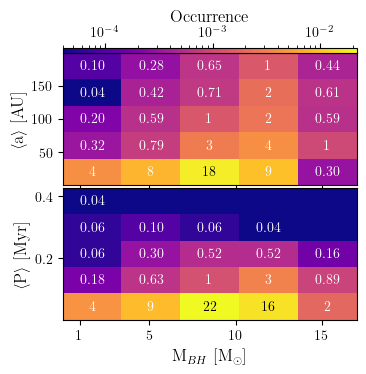

In [114]:
# Voxel plot of BH mass vs semimajor axis bins at the start of the BHMS lifetime
semimajor_axis_series_bound = [data['semimajoraxis'] for data in ms_bh_dict.values() if data['bound'] == True]
eccentricity_series_bound = [data['eccentricity'] for data in ms_bh_dict.values() if data['bound'] == True]
orbital_period_series_bound = [data['orbital_period'].value for data in ms_bh_dict.values() if data['bound'] == True]
mask = np.array([np.mean(a) < 200 for a in semimajor_axis_series_bound])
print(f"Systems with a < 200 AU: {np.sum(mask)}/{len(mask)}")

voxel_2dhistogram(
    metric_list=[semimajor_axis_series_bound, orbital_period_series_bound],
    metric_ylabels=[r'$\langle$a$\rangle$ [AU]', r'$\langle$P$\rangle$ [Myr]'],
    voxel_list=[mass_bh_bound, mass_bh_bound],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    # metric_ranges=[(0,200), (0, 1)],
    voxel_range=(0, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask],
    metric_unit_change=[1, 1e-6, 1],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4953,
    fig_size=(3.5, 3),
    # metric_ticks=[(40, 80, 120, 160,200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_T_average_alim_mask.png'
)

Creating 3x1 figure for voxel 2D histograms...

📊 Processing metric 1/3: $\langle$a$\rangle$ [AU]
Applied mask: 3009/4953 systems selected
  Valid data points: 3009
  Voxel range: (0, 17), Metric range: (0, 200)

📊 Processing metric 2/3: $\langle$e$\rangle$ 
Applied mask: 3009/4953 systems selected
  Valid data points: 3009
  Voxel range: (0, 17), Metric range: (0, 1)

📊 Processing metric 3/3: $\langle$P$\rangle$ [Myr]
Applied mask: 3009/4953 systems selected
  Valid data points: 3009
  Voxel range: (0, 17), Metric range: (0, 0.5)

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_e_P_average_alim_mask.png


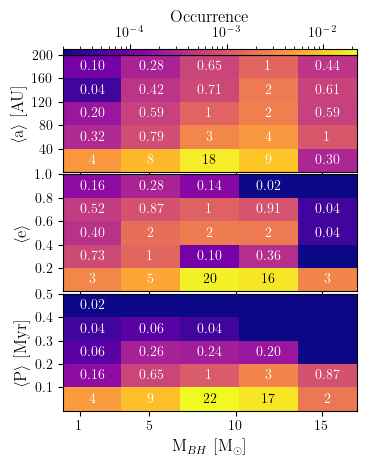

In [119]:
voxel_2dhistogram(
    metric_list=[semimajor_axis_series_bound, eccentricity_series_bound, orbital_period_series_bound],
    metric_ylabels=[r'$\langle$a$\rangle$ [AU]', r'$\langle$e$\rangle$ ', r'$\langle$P$\rangle$ [Myr]'],
    voxel_list=[mass_bh_bound, mass_bh_bound, mass_bh_bound],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    metric_ranges=[(0,200), (0, 1), (0, 0.5)],
    voxel_range=(0, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask, mask],
    metric_unit_change=[1, 1, 1e-6],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4953,
    fig_size=(3.5, 4),
    metric_ticks=[(40, 80, 120, 160, 200), (0.2, 0.4, 0.6, 0.8, 1.0), (0.1, 0.2, 0.3, 0.4, 0.5)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_e_P_average_alim_mask.png'
)

Systems with a < 200 AU: 3052/4953
Creating 2x1 figure for voxel 2D histograms...

📊 Processing metric 1/2: a [AU]
Applied mask: 3052/4953 systems selected
  Valid data points: 3052
  Voxel range: (1, 17), Metric range: (0, 200)

📊 Processing metric 2/2: P [Myr]
Applied mask: 3052/4953 systems selected
  Valid data points: 3052
  Voxel range: (1, 17), Metric range: (0, 1)

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_T_initial_alim_mask.png


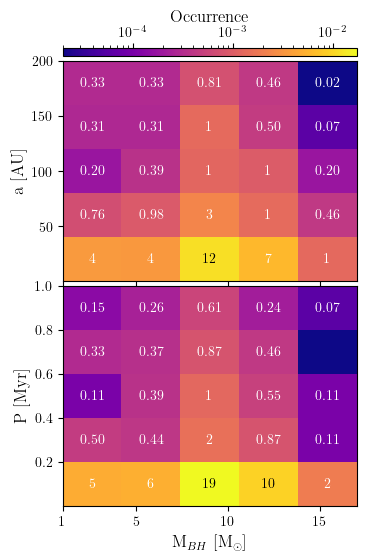

In [65]:
# Voxel plot of BH mass vs semimajor axis bins at the start of the BHMS lifetime
semimajor_axis_t0 = [data['semimajoraxis'][0] for data in ms_bh_dict.values() if data['bound'] == True]
orbital_period_t0 = [data['orbital_period'][0].value for data in ms_bh_dict.values() if data['bound'] == True]
eccentricity_t0 = [data['eccentricity'][0] for data in ms_bh_dict.values() if data['bound'] == True]
mass_bh_bound_t0 = [data['bh_mass'][0] for data in ms_bh_dict.values() if data['bound'] == True]
mask = np.array([np.mean(a) < 200 for a in semimajor_axis_t0])
print(f"Systems with a < 200 AU: {np.sum(mask)}/{len(mask)}")

voxel_2dhistogram(
    metric_list=[semimajor_axis_t0, orbital_period_t0],
    metric_ylabels=[r'a [AU]', r'P [Myr]'],
    voxel_list=[mass_bh_bound_t0, mass_bh_bound_t0],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    metric_ranges=[(0,200), (0, 1)],
    voxel_range=(1, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask],
    metric_unit_change=[1, 1e-6, 1],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4582,
    fig_size=(3.5, 5),
    metric_ticks=[(50, 100, 150, 200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_T_initial_alim_mask.png'
)

Creating 2x1 figure for voxel 2D histograms...

📊 Processing metric 1/2: a [AU]
Applied mask: 2957/4953 systems selected
  Valid data points: 2957
  Voxel range: (0, 17), Metric range: (0, 200)

📊 Processing metric 2/2: e
Applied mask: 2957/4953 systems selected
  Valid data points: 2957
  Voxel range: (0, 17), Metric range: (0, 1)

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_e_initial_alim_mask.png


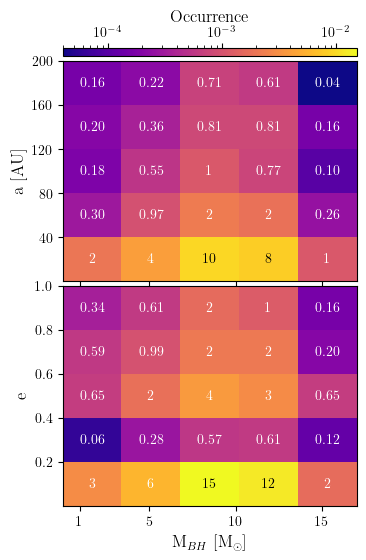

In [63]:
voxel_2dhistogram(
    metric_list=[semimajor_axis_t0, eccentricity_t0],
    metric_ylabels=[r'a [AU]', r'e'],
    voxel_list=[mass_bh_bound_t0, mass_bh_bound_t0],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    metric_ranges=[(0,200), (0, 1)],
    voxel_range=(0, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask],
    metric_unit_change=[1, 1, 1],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4953,
    fig_size=(3.5, 5),
    metric_ticks=[(40, 80, 120, 160, 200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_e_initial_alim_mask.png'
)

Systems with a < 200 AU: 2957/4953
Creating 2x1 figure for voxel 2D histograms...

📊 Processing metric 1/2: $\langle$a$\rangle$ [AU]
Applied mask: 2957/4953 systems selected
  Valid data points: 2957
  Voxel range: (1, 17), Metric range: (0, 200)

📊 Processing metric 2/2: $\langle$P$\rangle$ [Myr]
Applied mask: 2957/4953 systems selected
  Valid data points: 2957
  Voxel range: (1, 17), Metric range: (0, 1)

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_T_final_alim_mask.png


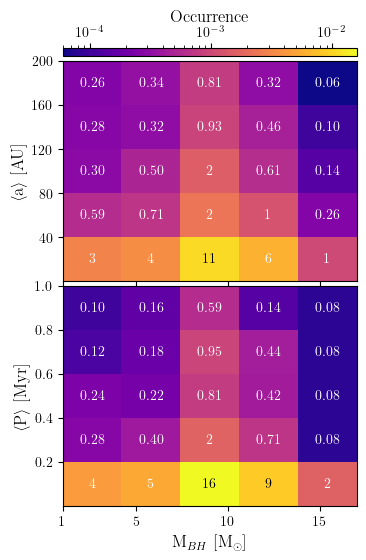

In [62]:
# Voxel plot of BH mass vs semimajor axis bins at the start of the BHMS lifetime
semimajor_axis_tf = [data['semimajoraxis'][-1] for data in ms_bh_dict.values() if data['bound'] == True]
orbital_period_tf = [data['orbital_period'][-1].value for data in ms_bh_dict.values() if data['bound'] == True]
eccentricity_tf = [data['eccentricity'][-1] for data in ms_bh_dict.values() if data['bound'] == True]
mass_bh_bound_tf = [data['bh_mass'][-1] for data in ms_bh_dict.values() if data['bound'] == True]
mask = np.array([np.mean(a) < 200 for a in semimajor_axis_tf])
print(f"Systems with a < 200 AU: {np.sum(mask)}/{len(mask)}")

voxel_2dhistogram(
    metric_list=[semimajor_axis_tf, orbital_period_tf],
    metric_ylabels=[r'$\langle$a$\rangle$ [AU]', r'$\langle$P$\rangle$ [Myr]'],
    voxel_list=[mass_bh_bound_tf, mass_bh_bound_tf],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    metric_ranges=[(0,200), (0, 1)],
    voxel_range=(1, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask],
    metric_unit_change=[1, 1e-6, 1],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4953,
    fig_size=(3.5, 5),
    metric_ticks=[(40, 80, 120, 160, 200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_T_final_alim_mask.png'
)

Creating 2x1 figure for voxel 2D histograms...

📊 Processing metric 1/2: $\langle$a$\rangle$ [AU]
Applied mask: 3052/4953 systems selected
  Valid data points: 3052
  Voxel range: (1, 17), Metric range: (0, 200)

📊 Processing metric 2/2: $\langle$e$\rangle$ 
Applied mask: 3052/4953 systems selected
  Valid data points: 3052
  Voxel range: (1, 17), Metric range: (0, 1)

✓ Figure saved to: /data/a.saricaoglu/repo/luxetenebrae/luxetenebrae/plots/voxel_bh_mass_vs_a_e_final_alim_mask.png


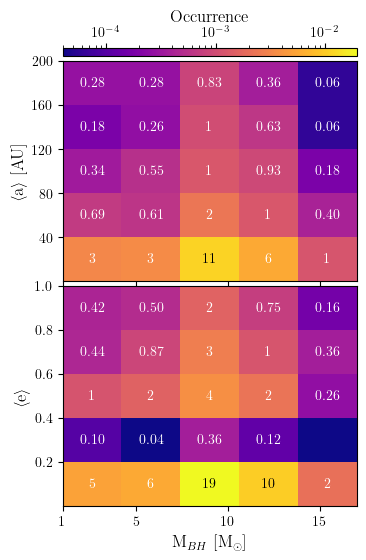

In [67]:
voxel_2dhistogram(
    metric_list=[semimajor_axis_tf, eccentricity_tf],
    metric_ylabels=[r'$\langle$a$\rangle$ [AU]', r'$\langle$e$\rangle$ '],
    voxel_list=[mass_bh_bound_tf, mass_bh_bound_tf],
    voxel_xlabel=r'M$_{BH}$ [M$_{\odot}$]',
    scale=['linear', 'linear', 'log'],
    metric_ranges=[(0,200), (0, 1)],
    voxel_range=(1, 17),
    v_lim=[None, None],
    voxel_bins=5,
    metric_bins=5,
    voxel_unit_change=1,
    masks=[mask, mask],
    metric_unit_change=[1, 1, 1],
    normalize=50000,
    annotate_bins=True,
    annotation_norm=4953,
    fig_size=(3.5, 5),
    metric_ticks=[(40, 80, 120, 160, 200), (0.2, 0.4, 0.6, 0.8, 1.0)],
    voxel_ticks=[1, 5, 10, 15],
    save=True,
    save_as='voxel_bh_mass_vs_a_e_final_alim_mask.png'
)